In [9]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
# create vistualizations for the wind and solar rasters

s1_wind = "../outputs_eolico/S1/weighted_suitability_S1_20261118_151743.tif"
s2_wind = "../outputs_eolico/S2/weighted_suitability_S2_20261118_152405.tif"
s3_wind = "../outputs_eolico/S3/weighted_suitability_S3_20261118_152626.tif"

colormap_wind = "Blues"
wind_intervals = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


C:\Users\mahone5n\AppData\Local\Temp\ipykernel_20976\2397556128.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.1, 1, 0.96])


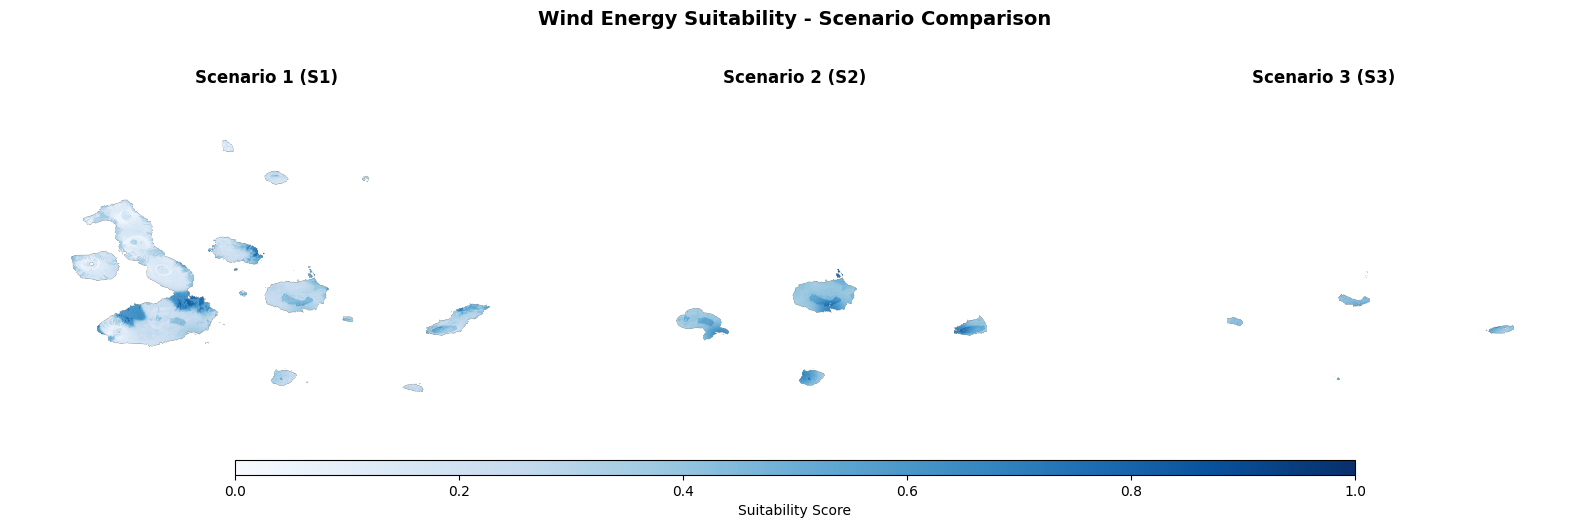

In [10]:


# Load and plot wind scenarios
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

scenarios = [
    {"path": s1_wind, "title": "Scenario 1 (S1)", "ax": axes[0]},
    {"path": s2_wind, "title": "Scenario 2 (S2)", "ax": axes[1]},
    {"path": s3_wind, "title": "Scenario 3 (S3)", "ax": axes[2]},
]

for scenario in scenarios:
    with rasterio.open(scenario["path"]) as src:
        data = src.read(1)
    
    # Mask out nodata values
    data = np.ma.masked_where(data == -9999, data)
    
    # Use continuous normalization to see all values
    im = scenario["ax"].imshow(data, cmap=colormap_wind, vmin=0, vmax=1, aspect="auto")
    scenario["ax"].set_title(scenario["title"], fontsize=12, fontweight="bold")
    scenario["ax"].axis("off")

# Add horizontal colorbar underneath
cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.03])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal', label="Suitability Score")

plt.suptitle("Wind Energy Suitability - Scenario Comparison", 
             fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0.1, 1, 0.96])
plt.show()

In [ ]:
# Island-specific maps with optional high-value outline and save to folder
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from rasterio.windows import Window, from_bounds, transform as window_transform
from matplotlib.ticker import FuncFormatter
from pathlib import Path

Figures will be saved to: D:\Erin\HyGalapagos_Repo\idoneidad_hygalapagos\outputs_eolico\figures

Generating maps for Scenario S1...
  âœ“ Saved: S1_Isabela.png


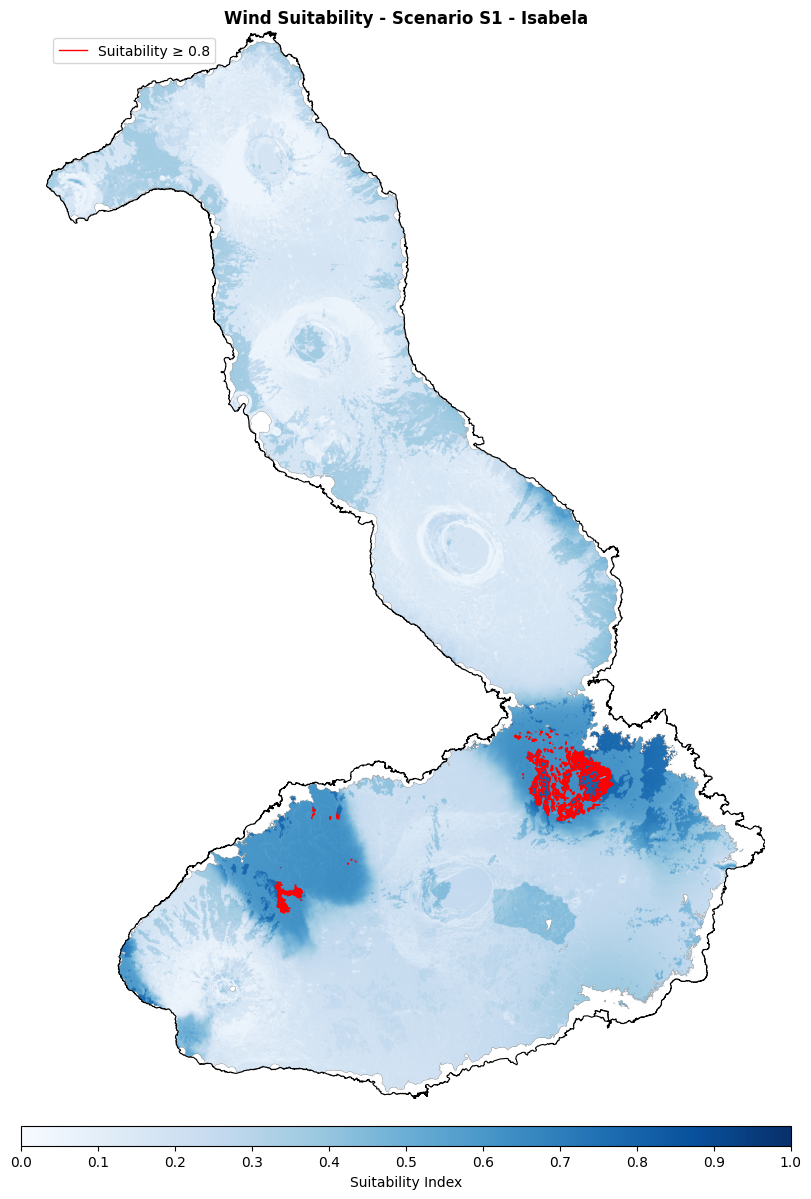

  âœ“ Generated map for Isabela
  âœ“ Saved: S1_Santa_Cruz.png


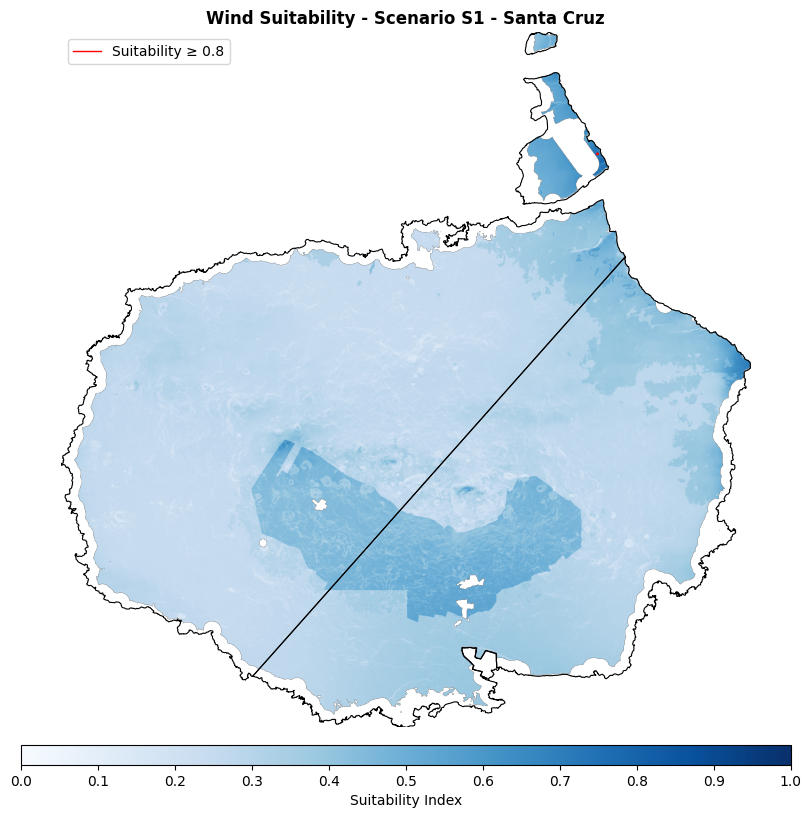

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S1_San_Cristobal.png


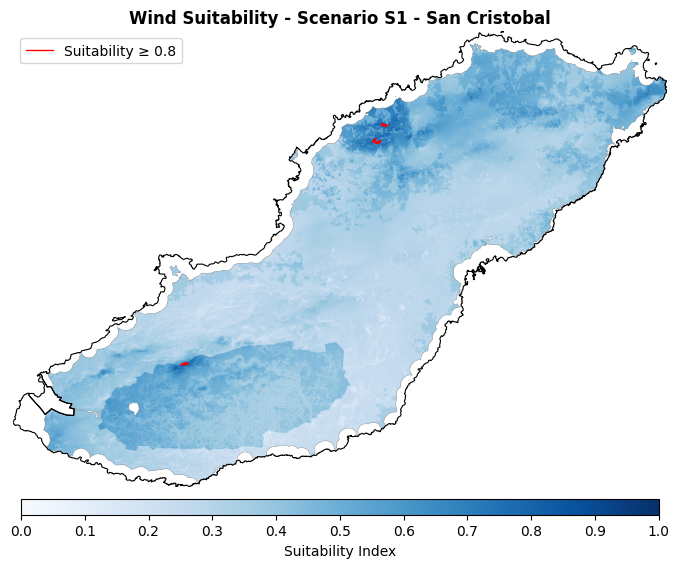

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S1_Floreana.png


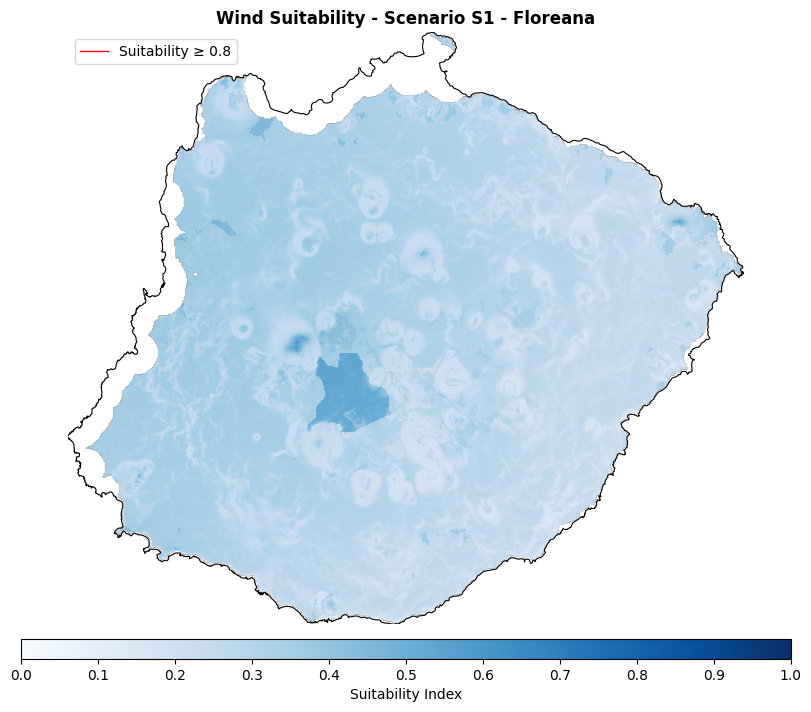

  âœ“ Generated map for Floreana

Generating maps for Scenario S2...
  âœ“ Saved: S2_Isabela.png


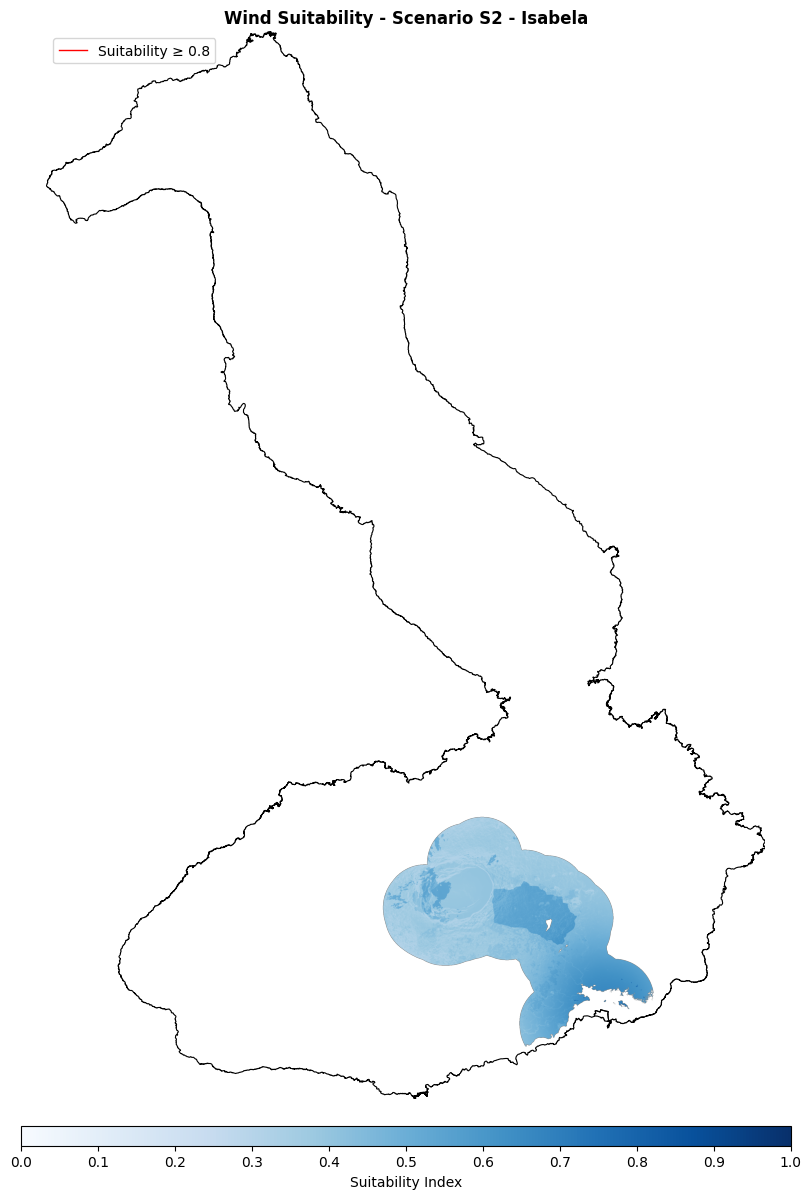

  âœ“ Generated map for Isabela
  âœ“ Saved: S2_Santa_Cruz.png


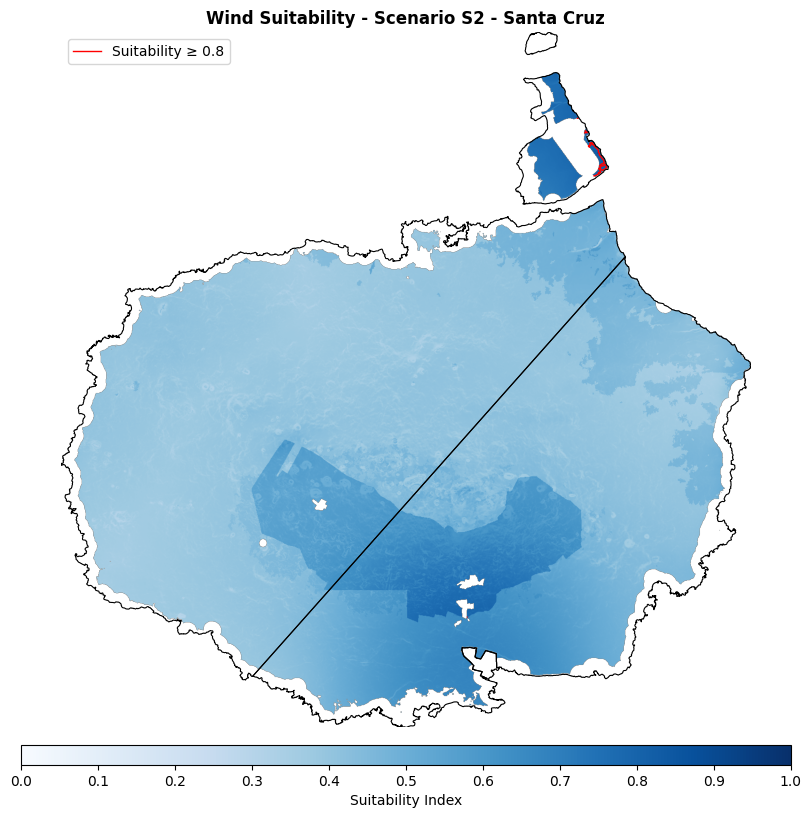

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S2_San_Cristobal.png


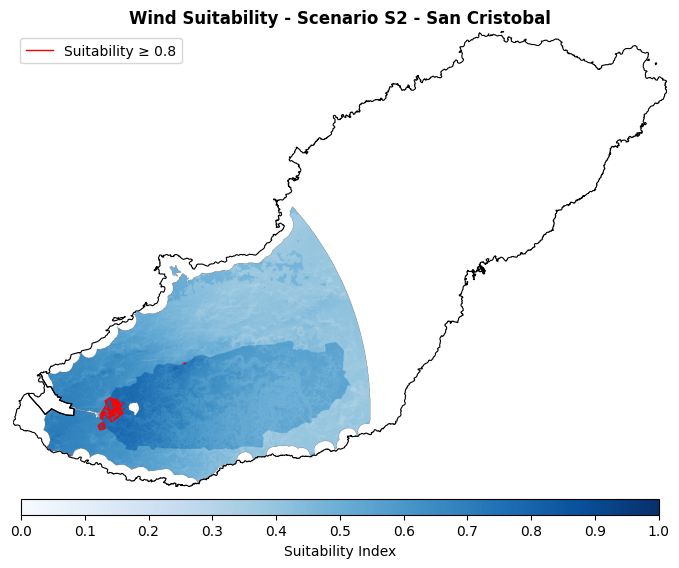

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S2_Floreana.png


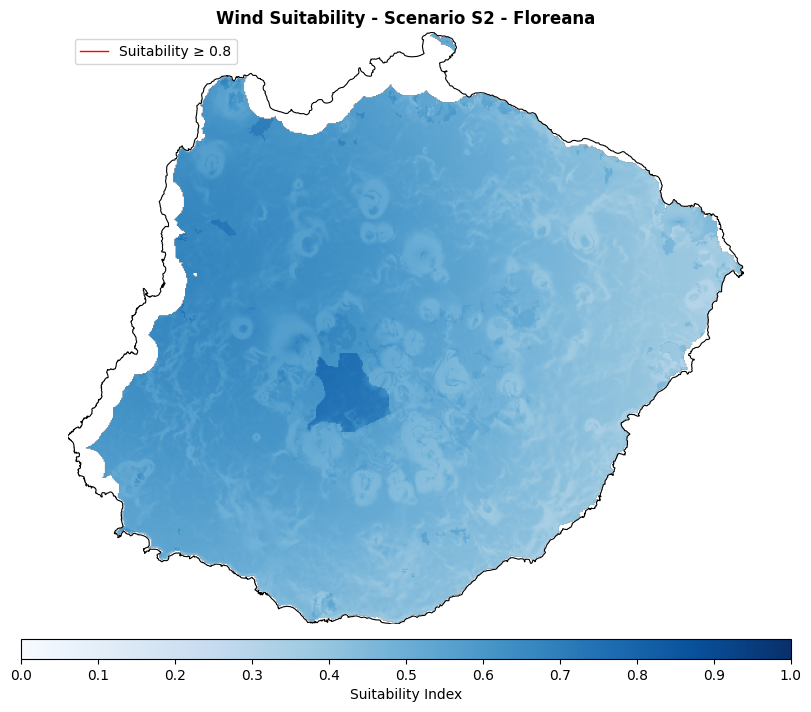

  âœ“ Generated map for Floreana

Generating maps for Scenario S3...
  âœ“ Saved: S3_Isabela.png


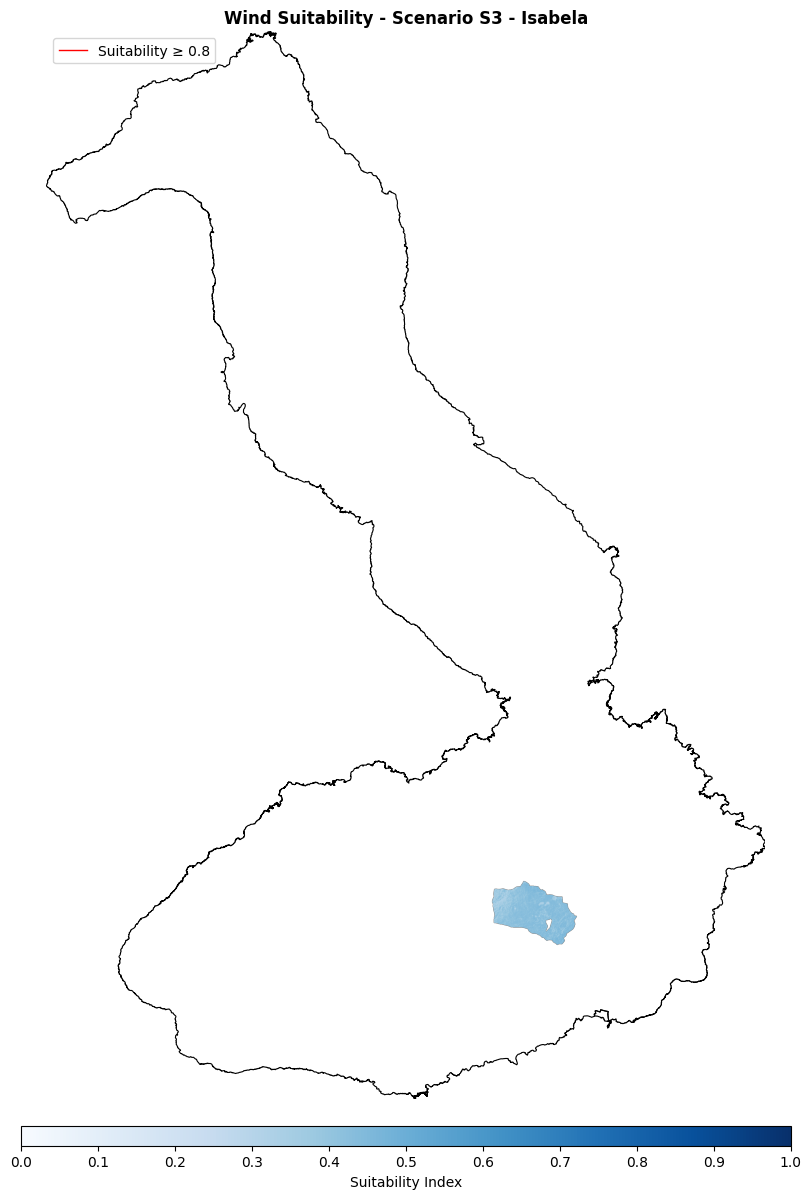

  âœ“ Generated map for Isabela
  âœ“ Saved: S3_Santa_Cruz.png


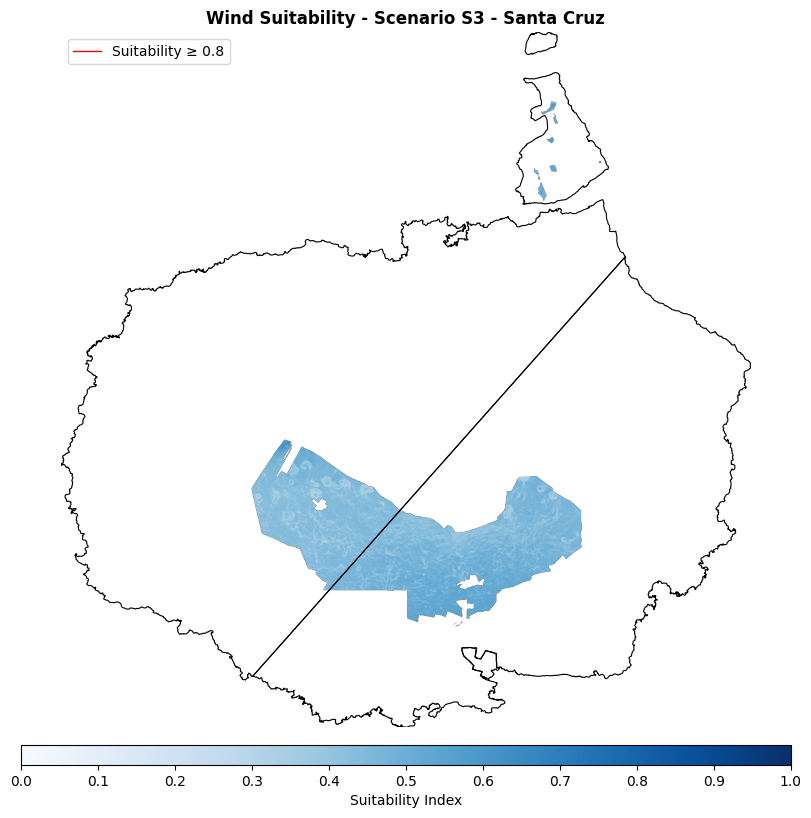

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S3_San_Cristobal.png


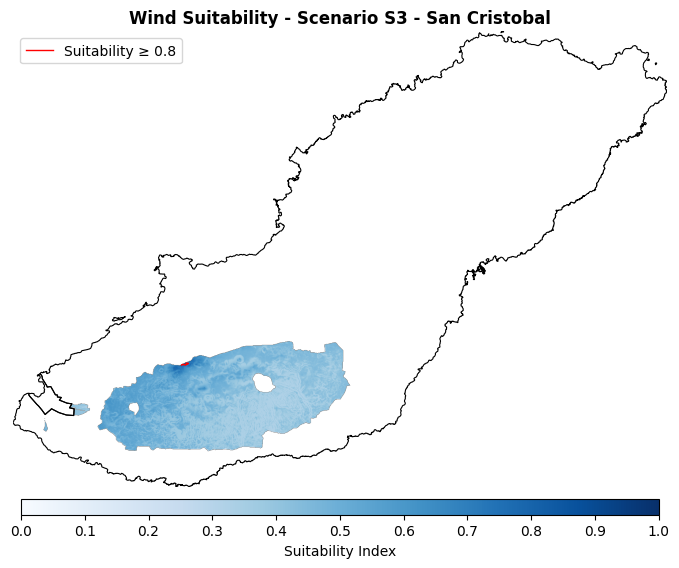

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S3_Floreana.png


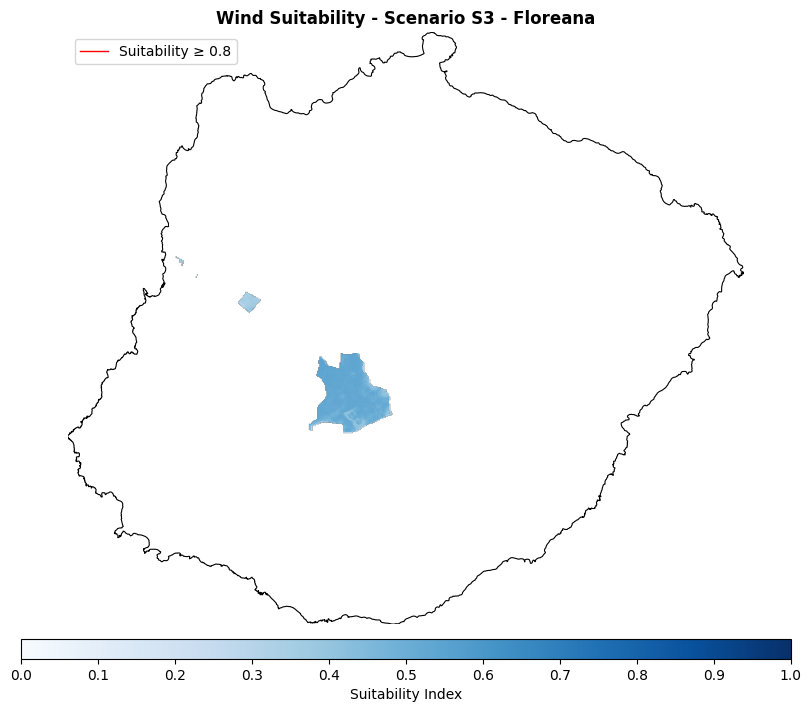

  âœ“ Generated map for Floreana


In [27]:
# Island-specific maps with optional high-value outline and save to folder
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from rasterio.windows import Window, from_bounds, transform as window_transform
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from pathlib import Path

# Toggle for outlining high-value areas (>0.8)
OUTLINE_HIGH_VALUES = True
HIGH_VALUE_THRESHOLD = 0.8
OUTLINE_COLOR = "red"
OUTLINE_LINEWIDTH = 1

# Toggle for saving figures
SAVE_FIGURES = True
FIGURE_OUTPUT_DIR = Path("D:\\Erin\\HyGalapagos_Repo\\idoneidad_hygalapagos\\outputs_eolico\\figures")

# Create output directory if saving is enabled
if SAVE_FIGURES:
    FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Figures will be saved to: {FIGURE_OUTPUT_DIR.resolve()}")

# Define island shapefiles
BASE_PATH = "../inputs/01_Organizacion_Territorial"
island_files = {
    "Isabela": f"{BASE_PATH}/solo_isabela.shp",
    "Santa Cruz": f"{BASE_PATH}/santa_cruz_baltra.shp",
    "San Cristobal": f"{BASE_PATH}/san_cristobal.shp",
    "Floreana": f"{BASE_PATH}/floreana.shp",
}

# Define wind scenarios
scenarios = {
    "S1": s1_wind,
    "S2": s2_wind,
    "S3": s3_wind,
}

# Island order for consistent display
island_order = ("Isabela", "Santa Cruz", "San Cristobal", "Floreana")

# Generate maps for each scenario and island
for scenario_name, raster_path in scenarios.items():
    print(f"\nGenerating maps for Scenario {scenario_name}...")
    
    with rasterio.open(raster_path) as src:
        raster_data = src.read(1)
        raster_profile = src.profile
        raster_transform = src.transform
    
    # Mask nodata values
    raster_data = np.ma.masked_where(raster_data == -9999, raster_data)
    
    for island_name in island_order:
        # Read island boundary
        island_boundary = gpd.read_file(island_files[island_name])
        island_boundary = island_boundary.to_crs(raster_profile["crs"])
        bounds_coords = island_boundary.total_bounds
        
        # Calculate window for this island
        window = from_bounds(*bounds_coords, transform=raster_transform)
        window = window.round_offsets().round_lengths()
        
        raw_row_start = int(window.row_off)
        raw_col_start = int(window.col_off)
        raster_height, raster_width = raster_data.shape
        
        row_start = max(0, raw_row_start)
        col_start = max(0, raw_col_start)
        row_stop = min(raster_height, raw_row_start + int(window.height))
        col_stop = min(raster_width, raw_col_start + int(window.width))
        
        if row_start >= row_stop or col_start >= col_stop:
            print(f"  Skipping {island_name}: island boundary does not intersect raster extent")
            continue
        
        # Extract island data
        window_obj = Window(col_start, row_start, col_stop - col_start, row_stop - row_start)
        window_slice = (slice(row_start, row_stop), slice(col_start, col_stop))
        island_data = raster_data[window_slice]
        island_transform = window_transform(window_obj, raster_transform)
        
        # Create mask for pixels inside island boundary
        inside_island = geometry_mask(
            island_boundary.geometry,
            out_shape=island_data.shape,
            transform=island_transform,
            invert=True,
        )
        
        # Mask data to only pixels inside island
        island_data = np.ma.masked_where(~inside_island, island_data)
        
        # Calculate extent for imshow
        height, width = island_data.shape
        west, south, east, north = array_bounds(height, width, island_transform)
        map_extent = [west, east, south, north]
        
        # Create figure
        map_width = 8.0
        map_height = max(4.5, map_width * (bounds_coords[3] - bounds_coords[1]) / (bounds_coords[2] - bounds_coords[0]))
        fig, ax = plt.subplots(figsize=(map_width, map_height), constrained_layout=True)
        
        # Plot with continuous normalization (shows all values clearly)
        im = ax.imshow(
            island_data,
            cmap=colormap_wind,
            vmin=0,
            vmax=1,
            extent=map_extent,
            origin="upper",
        )
        
        # Add optional outline for high-value areas (>0.8)
        if OUTLINE_HIGH_VALUES:
            high_value_mask = (island_data >= HIGH_VALUE_THRESHOLD).astype(float)
            ax.contour(
                high_value_mask,
                levels=[0.5],
                colors=OUTLINE_COLOR,
                linewidths=OUTLINE_LINEWIDTH,
                extent=map_extent,
                origin="upper",
            )
        
        # Add island boundary
        island_boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)
        
        # Set extent and aspect
        ax.set_xlim(bounds_coords[0], bounds_coords[2])
        ax.set_ylim(bounds_coords[1], bounds_coords[3])
        ax.set_aspect("equal")
        ax.axis("off")
        
        # Title and colorbar with proper decimal formatting
        ax.set_title(f"Wind Suitability - Scenario {scenario_name} - {island_name}", fontsize=12, fontweight="bold")
        
        # Create colorbar with clean decimal ticks (0.0, 0.1, 0.2, ... 1.0)
        colorbar = fig.colorbar(
            im,
            ax=ax,
            orientation="horizontal",
            fraction=0.035,
            pad=0.025,
            aspect=40,
            ticks=np.arange(0, 1.1, 0.1),
        )
        colorbar.ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: f'{x:.1f}'))
        colorbar.set_label("Suitability Index", labelpad=4)
        
        # Add legend for threshold outline if enabled
        if OUTLINE_HIGH_VALUES:
            legend_elements = [
                Line2D([0], [0], color=OUTLINE_COLOR, linewidth=OUTLINE_LINEWIDTH, label=f"Suitability â‰¥ {HIGH_VALUE_THRESHOLD:.1f}")
            ]
            ax.legend(handles=legend_elements, loc="upper left", fontsize=10, frameon=True)
        
        # Save figure if enabled
        if SAVE_FIGURES:
            # Clean island name for filename (replace spaces)
            island_clean = island_name.replace(" ", "_")
            filename = FIGURE_OUTPUT_DIR / f"{scenario_name}_{island_clean}.png"
            fig.savefig(filename, dpi=300, bbox_inches="tight")
            print(f"  âœ“ Saved: {filename.name}")
        
        plt.show()
        print(f"  âœ“ Generated map for {island_name}")
        
        plt.close(fig)

Figures will be saved to: D:\Erin\HyGalapagos_Repo\idoneidad_hygalapagos\outputs_solar\figures

Generating maps for Scenario S1...
  âœ“ Saved: S1_Isabela.png


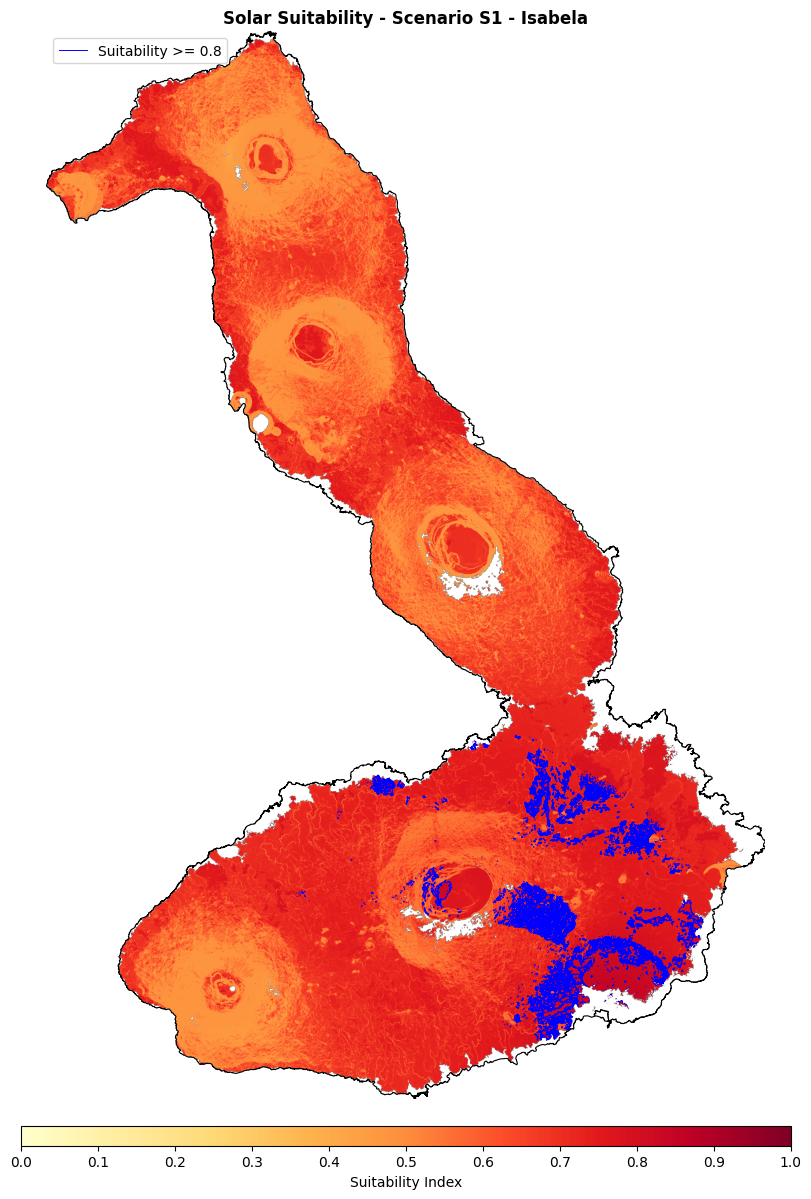

  âœ“ Generated map for Isabela
  âœ“ Saved: S1_Santa_Cruz.png


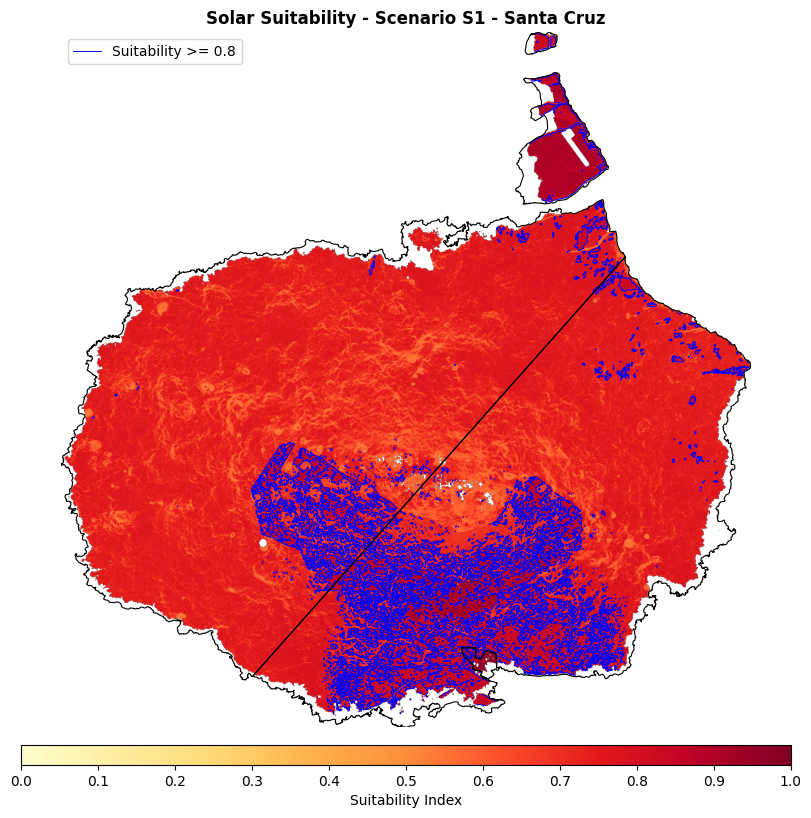

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S1_San_Cristobal.png


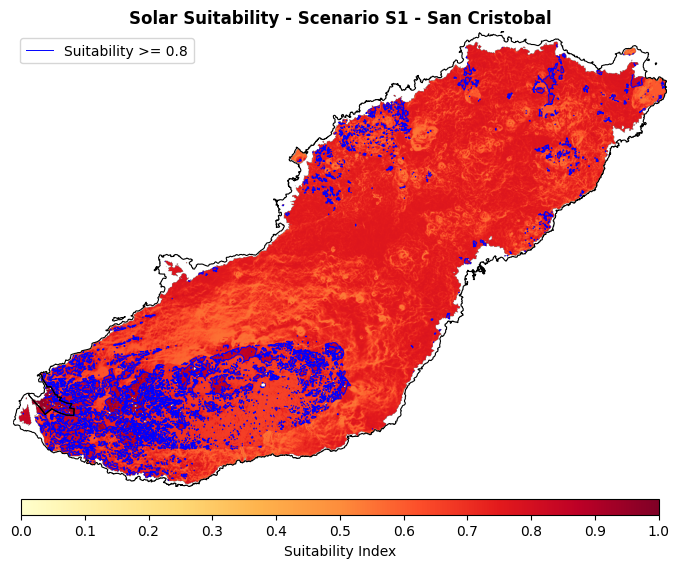

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S1_Floreana.png


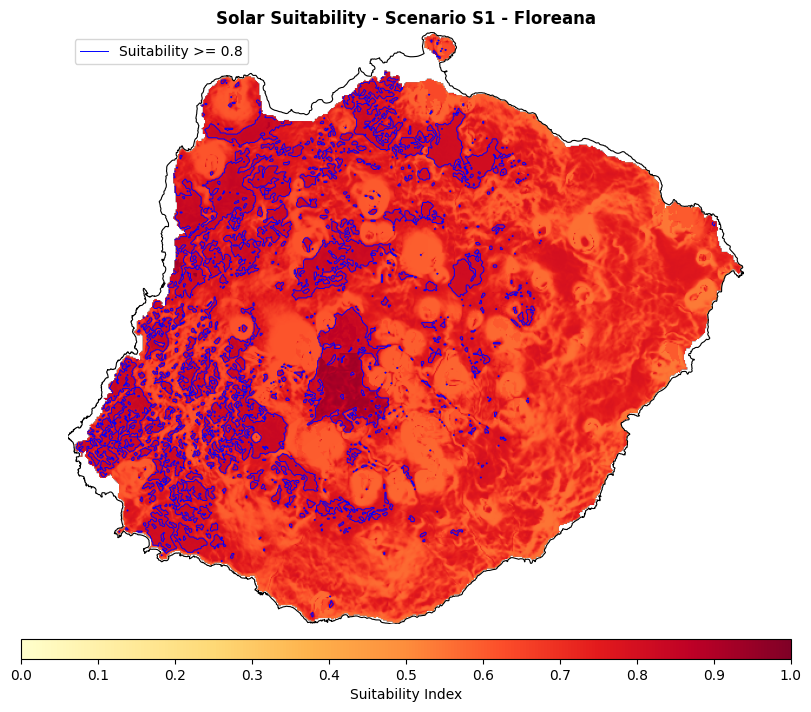

  âœ“ Generated map for Floreana

Generating maps for Scenario S2...
  âœ“ Saved: S2_Isabela.png


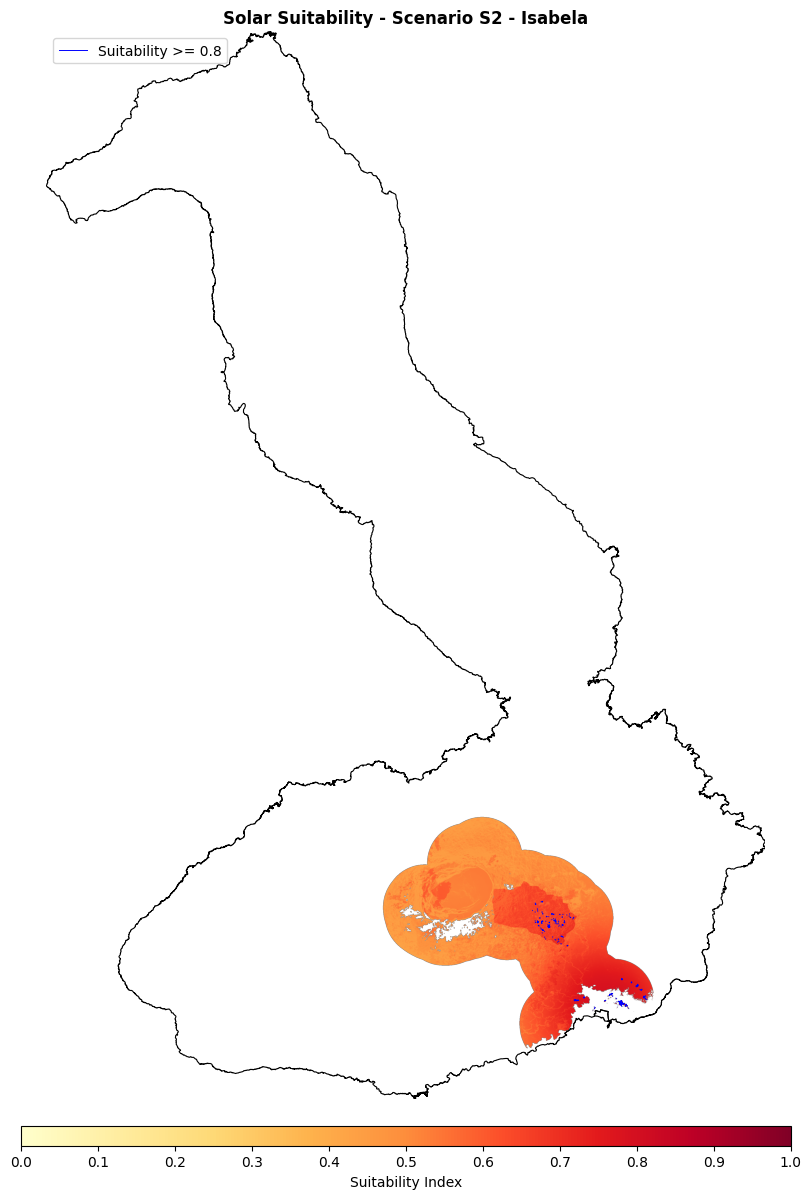

  âœ“ Generated map for Isabela
  âœ“ Saved: S2_Santa_Cruz.png


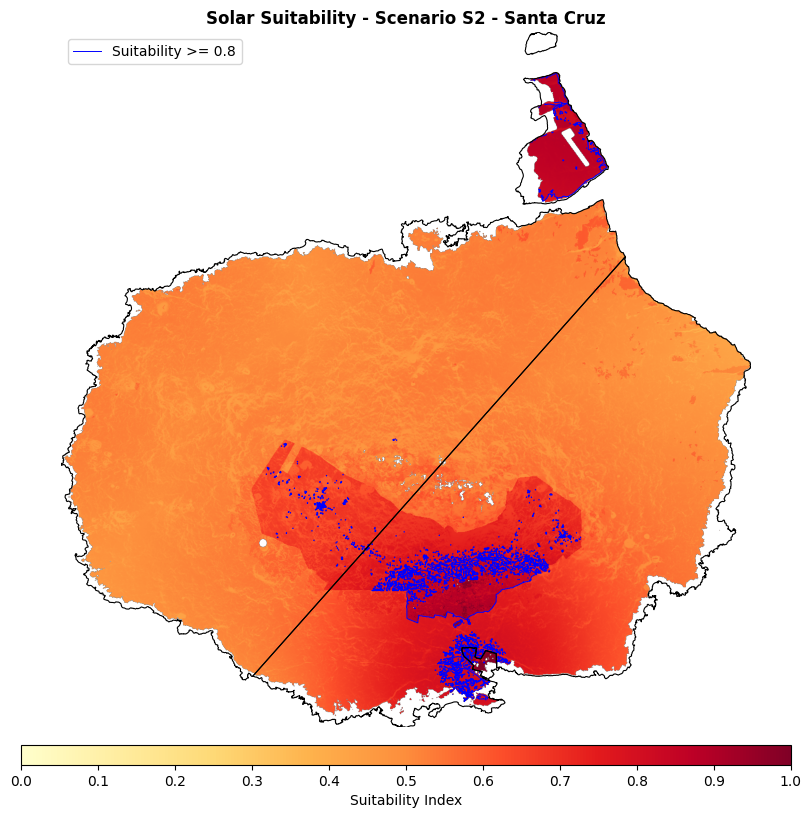

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S2_San_Cristobal.png


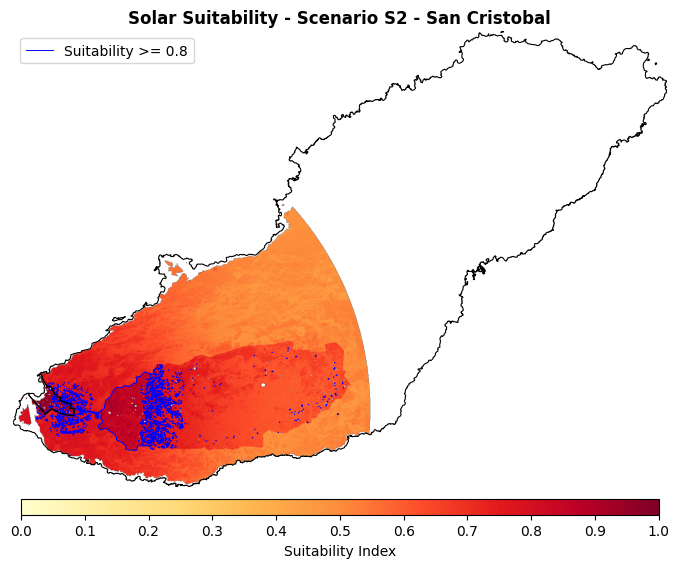

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S2_Floreana.png


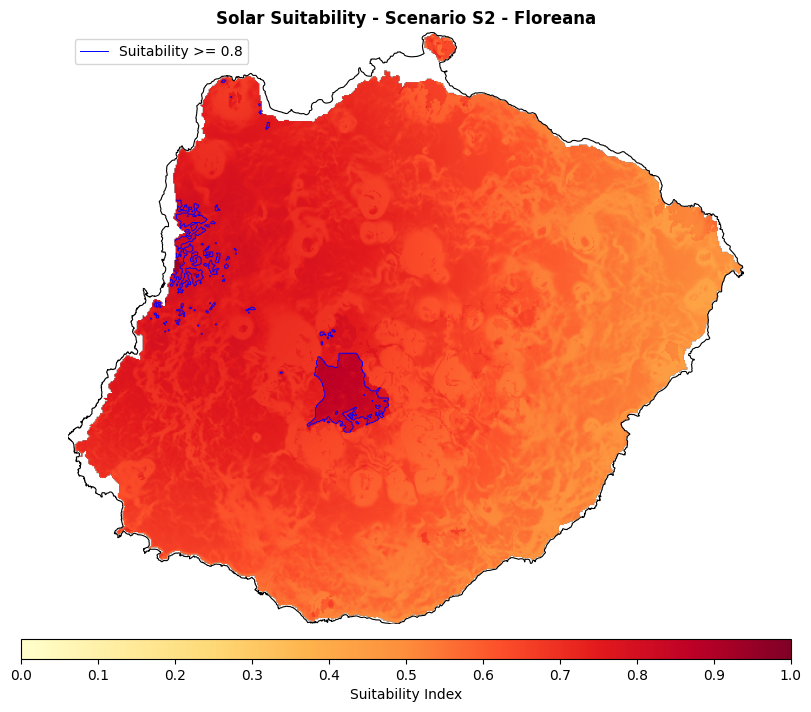

  âœ“ Generated map for Floreana

Generating maps for Scenario S3...
  âœ“ Saved: S3_Isabela.png


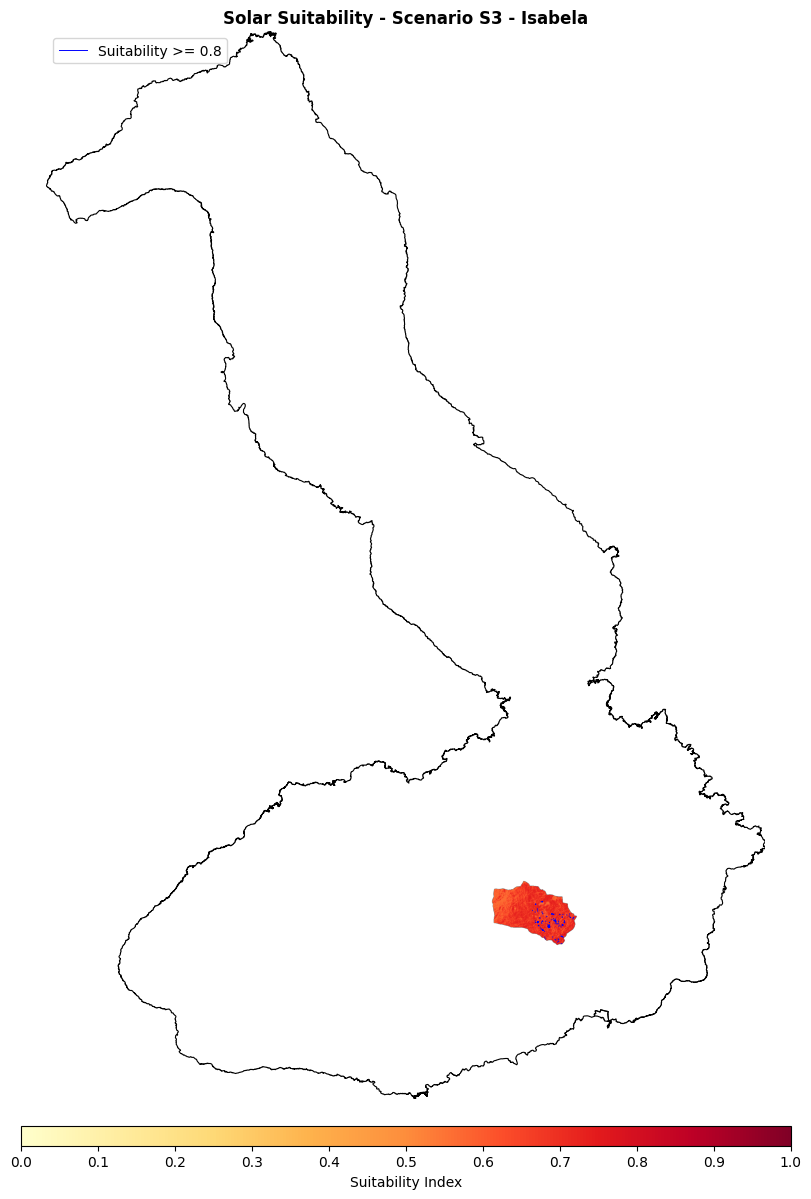

  âœ“ Generated map for Isabela
  âœ“ Saved: S3_Santa_Cruz.png


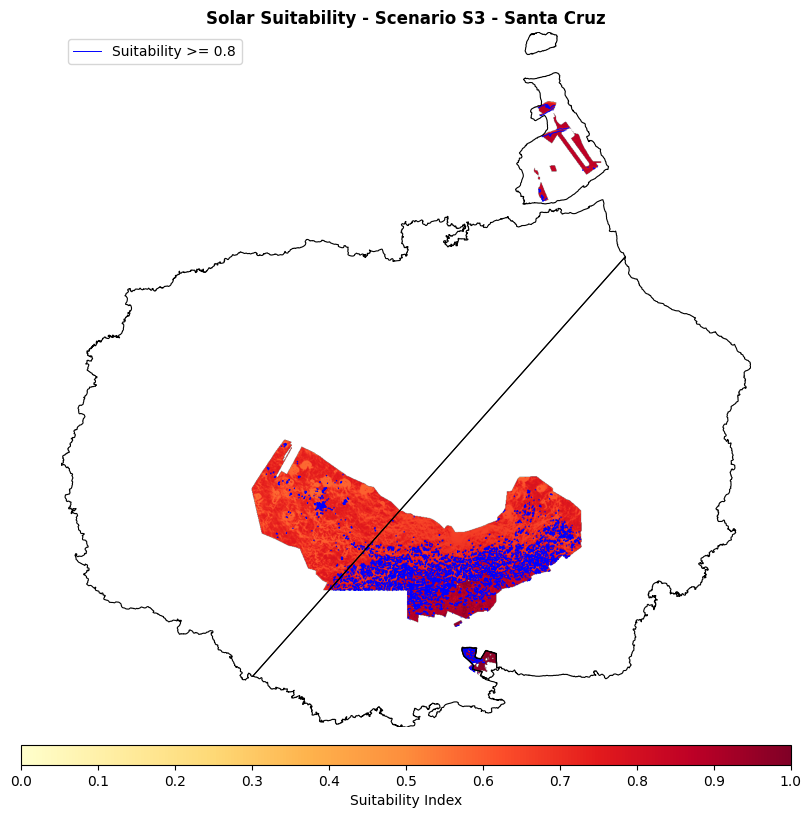

  âœ“ Generated map for Santa Cruz
  âœ“ Saved: S3_San_Cristobal.png


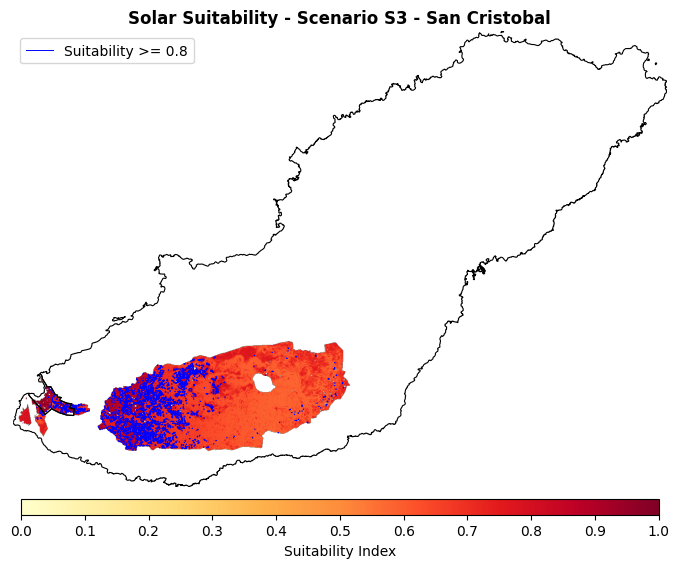

  âœ“ Generated map for San Cristobal
  âœ“ Saved: S3_Floreana.png


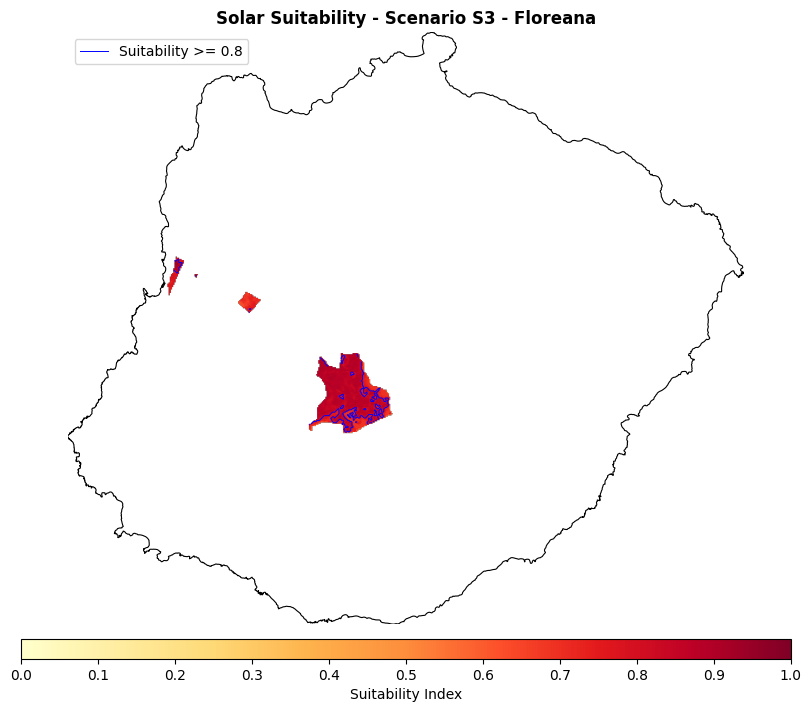

  âœ“ Generated map for Floreana


In [29]:
# Toggle for outlining high-value areas (>0.8)

OUTLINE_HIGH_VALUES = True

HIGH_VALUE_THRESHOLD = 0.8

OUTLINE_COLOR = "blue"

OUTLINE_LINEWIDTH = 0.7



# Toggle for saving figures

SAVE_FIGURES = True

FIGURE_OUTPUT_DIR = Path("D:\\Erin\\HyGalapagos_Repo\\idoneidad_hygalapagos\\outputs_solar\\figures")



# Create output directory if saving is enabled

if SAVE_FIGURES:

    FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    print(f"Figures will be saved to: {FIGURE_OUTPUT_DIR.resolve()}")



# Define island shapefiles

BASE_PATH = "../inputs/01_Organizacion_Territorial"

island_files = {

    "Isabela": f"{BASE_PATH}/solo_isabela.shp",

    "Santa Cruz": f"{BASE_PATH}/santa_cruz_baltra.shp",

    "San Cristobal": f"{BASE_PATH}/san_cristobal.shp",

    "Floreana": f"{BASE_PATH}/floreana.shp",

}



s1_solar = "../outputs_solar\\S1\\weighted_suitability_S1_20261120_101511.tif"

s2_solar = "../outputs_solar\\S2\\weighted_suitability_S2_20261120_102047.tif"

s3_solar = "../outputs_solar\\S3\\weighted_suitability_S3_20261120_102814.tif"



# Define solar scenarios

scenarios = {

    "S1": s1_solar,

    "S2": s2_solar,

    "S3": s3_solar,

}



colormap_solar = "YlOrRd"



# Island order for consistent display

island_order = ("Isabela", "Santa Cruz", "San Cristobal", "Floreana")



# Generate maps for each scenario and island

for scenario_name, raster_path in scenarios.items():

    print(f"\nGenerating maps for Scenario {scenario_name}...")

    

    with rasterio.open(raster_path) as src:

        raster_data = src.read(1)

        raster_profile = src.profile

        raster_transform = src.transform

    

    # Mask nodata values

    raster_data = np.ma.masked_where(raster_data == -9999, raster_data)

    

    for island_name in island_order:

        # Read island boundary

        island_boundary = gpd.read_file(island_files[island_name])

        island_boundary = island_boundary.to_crs(raster_profile["crs"])

        bounds_coords = island_boundary.total_bounds

        

        # Calculate window for this island

        window = from_bounds(*bounds_coords, transform=raster_transform)

        window = window.round_offsets().round_lengths()

        

        raw_row_start = int(window.row_off)

        raw_col_start = int(window.col_off)

        raster_height, raster_width = raster_data.shape

        

        row_start = max(0, raw_row_start)

        col_start = max(0, raw_col_start)

        row_stop = min(raster_height, raw_row_start + int(window.height))

        col_stop = min(raster_width, raw_col_start + int(window.width))

        

        if row_start >= row_stop or col_start >= col_stop:

            print(f"  Skipping {island_name}: island boundary does not intersect raster extent")

            continue

        

        # Extract island data

        window_obj = Window(col_start, row_start, col_stop - col_start, row_stop - row_start)

        window_slice = (slice(row_start, row_stop), slice(col_start, col_stop))

        island_data = raster_data[window_slice]

        island_transform = window_transform(window_obj, raster_transform)

        

        # Create mask for pixels inside island boundary

        inside_island = geometry_mask(

            island_boundary.geometry,

            out_shape=island_data.shape,

            transform=island_transform,

            invert=True,

        )

        

        # Mask data to only pixels inside island

        island_data = np.ma.masked_where(~inside_island, island_data)

        

        # Calculate extent for imshow

        height, width = island_data.shape

        west, south, east, north = array_bounds(height, width, island_transform)

        map_extent = [west, east, south, north]

        

        # Create figure

        map_width = 8.0

        map_height = max(4.5, map_width * (bounds_coords[3] - bounds_coords[1]) / (bounds_coords[2] - bounds_coords[0]))

        fig, ax = plt.subplots(figsize=(map_width, map_height), constrained_layout=True)

        

        # Plot with continuous normalization (shows all values clearly)

        im = ax.imshow(

            island_data,

            cmap=colormap_solar,

            vmin=0,

            vmax=1,

            extent=map_extent,

            origin="upper",

        )

        

        # Add optional outline for high-value areas (>0.8)

        if OUTLINE_HIGH_VALUES:

            high_value_mask = (island_data >= HIGH_VALUE_THRESHOLD).astype(float)

            ax.contour(

                high_value_mask,

                levels=[0.5],

                colors=OUTLINE_COLOR,

                linewidths=OUTLINE_LINEWIDTH,

                extent=map_extent,

                origin="upper",

            )

        

        # Add island boundary

        island_boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)

        

        # Set extent and aspect

        ax.set_xlim(bounds_coords[0], bounds_coords[2])

        ax.set_ylim(bounds_coords[1], bounds_coords[3])

        ax.set_aspect("equal")

        ax.axis("off")

        

        # Title and colorbar with proper decimal formatting

        ax.set_title(f"Solar Suitability - Scenario {scenario_name} - {island_name}", fontsize=12, fontweight="bold")

        

        # Create colorbar with clean decimal ticks (0.0, 0.1, 0.2, ... 1.0)

        colorbar = fig.colorbar(

            im,

            ax=ax,

            orientation="horizontal",

            fraction=0.035,

            pad=0.025,

            aspect=40,

            ticks=np.arange(0, 1.1, 0.1),

        )

        colorbar.ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: f'{x:.1f}'))

        colorbar.set_label("Suitability Index", labelpad=4)
        # Add legend for threshold outline if enabled
        if OUTLINE_HIGH_VALUES:
            from matplotlib.lines import Line2D
            legend_elements = [
                Line2D([0], [0], color=OUTLINE_COLOR, linewidth=OUTLINE_LINEWIDTH, label=f"Suitability >= {HIGH_VALUE_THRESHOLD:.1f}")
            ]
            ax.legend(handles=legend_elements, loc="upper left", fontsize=10, frameon=True)

        

        # Save figure if enabled

        if SAVE_FIGURES:

            # Clean island name for filename (replace spaces)

            island_clean = island_name.replace(" ", "_")

            filename = FIGURE_OUTPUT_DIR / f"{scenario_name}_{island_clean}.png"

            fig.savefig(filename, dpi=300, bbox_inches="tight")

            print(f"  âœ“ Saved: {filename.name}")

        

        plt.show()

        print(f"  âœ“ Generated map for {island_name}")

        

        plt.close(fig)

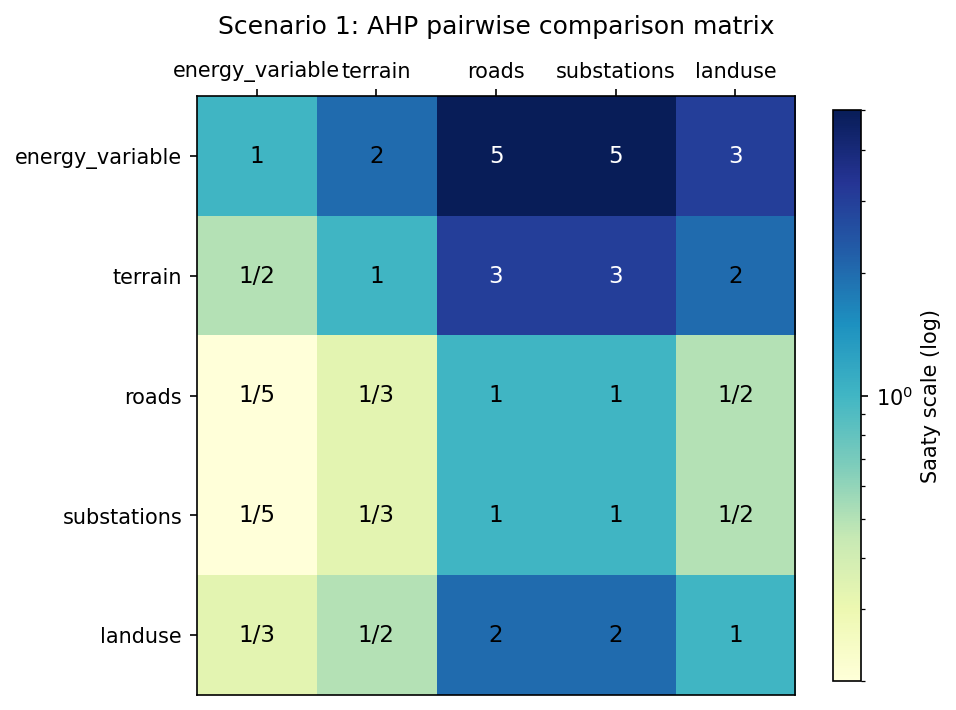

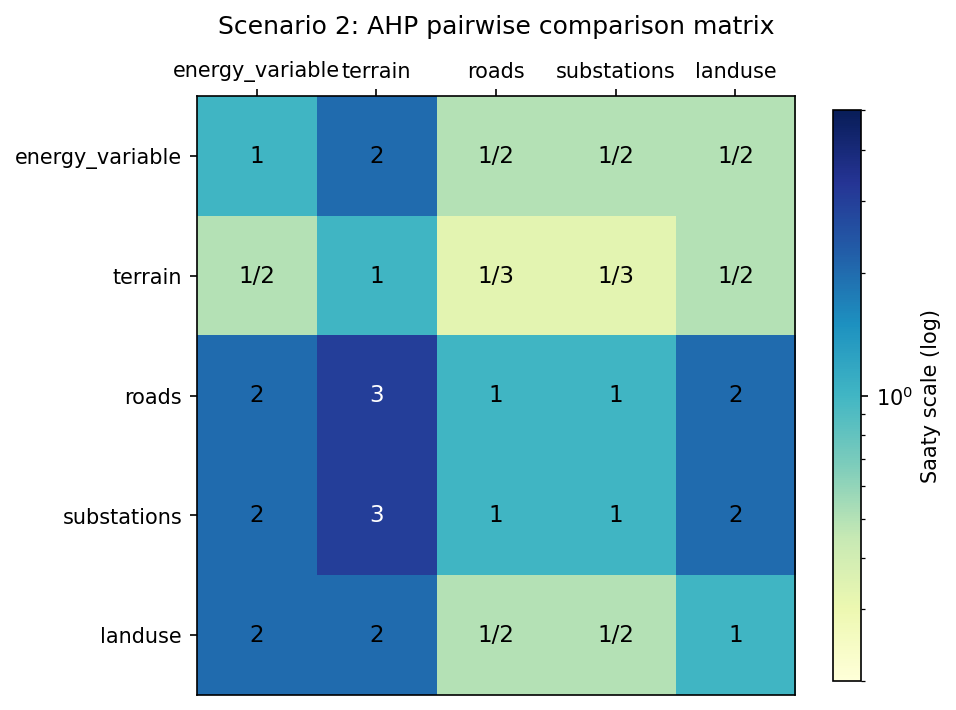

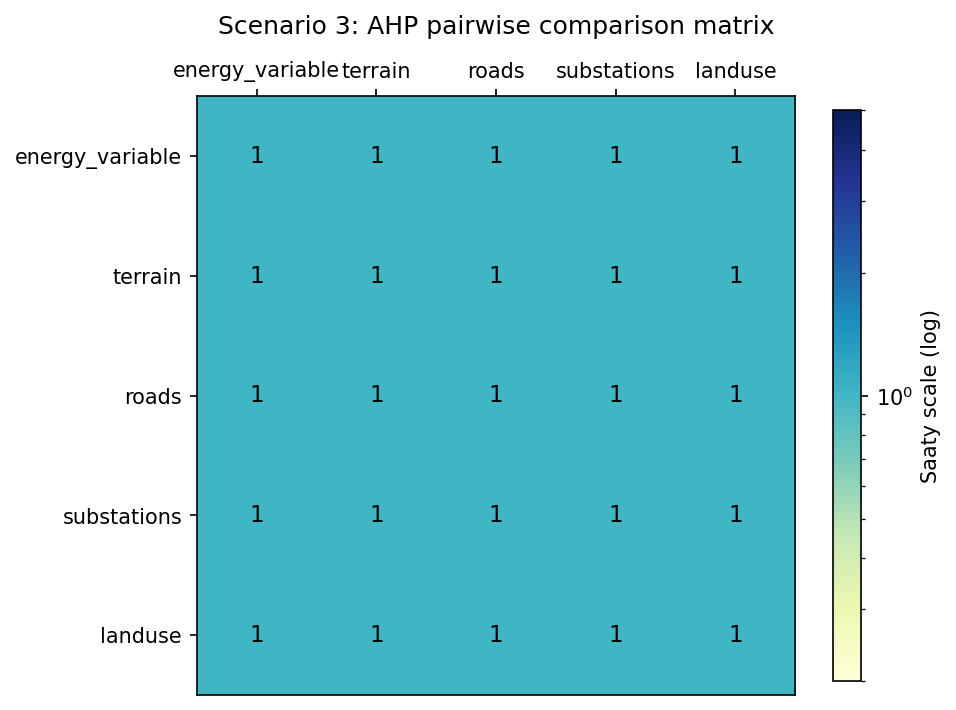

In [3]:
import numpy as np
import matplotlib.pyplot as plt

CRITERIA = ["energy_variable", "terrain", "roads", "substations", "landuse"]

# AHP pairwise comparison matrices (Saaty scale), rows/columns in CRITERIA order.
AHP_MATRICES = {
    "Scenario 1": np.array([  # PV-priority comparisons
        [1,   2,   5,   5,   3],
        [1/2, 1,   3,   3,   2],
        [1/5, 1/3, 1,   1,   1/2],
        [1/5, 1/3, 1,   1,   1/2],
        [1/3, 1/2, 2,   2,   1],
    ]),
    "Scenario 2": np.array([  # accessibility-priority comparisons
        [1,   2,   1/2, 1/2, 1/2],
        [1/2, 1,   1/3, 1/3, 1/2],
        [2,   3,   1,   1,   2],
        [2,   3,   1,   1,   2],
        [2,   2,   1/2, 1/2, 1],
    ]),
    "Scenario 3": np.array([  # equal importance
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1],
    ]),
}

for scenario, matrix in AHP_MATRICES.items():
    fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=150)
    im = ax.imshow(matrix, cmap="YlGnBu", norm="log", vmin=1/5, vmax=5)
    ax.set_xticks(range(len(CRITERIA)), labels=CRITERIA)
    ax.set_yticks(range(len(CRITERIA)), labels=CRITERIA)
    ax.xaxis.tick_top()
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]
            label = f"{value:g}" if value >= 1 else f"1/{round(1 / value)}"
            ax.text(j, i, label, ha="center", va="center", fontsize=11,
                    color="white" if value >= 3 else "black")
    ax.set_title(f"{scenario}: AHP pairwise comparison matrix", pad=30)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Saaty scale (log)")
    fig.tight_layout()
    plt.show()
    plt.close(fig)